# 🛒 Online Retail II – Customer Segmentation, Repeat-Purchase Prediction & Spend Forecast

## 🎯 Business Problem
An online gift-ware shop sells to thousands of customers. The owner wants three answers:
1. **Who are my customer groups?** (VIP, regular, low value ...) → *Clustering*
2. **Which customers will buy again in the next 90 days?** → *Classification*
3. **How much will a returning customer spend in the next 90 days?** → *Regression*

With these answers the shop can send offers to the right people instead of everyone.

## 📦 Dataset
**Online Retail II** (UK online store, Dec 2009 – Dec 2011). Columns: `Invoice, StockCode, Description, Quantity, InvoiceDate, Price, Customer ID, Country`.

## 🧠 Models used
Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, Random Forest, Linear Regression, K-Means, Hierarchical Clustering.

## 🧭 Plan of the notebook
Load → Clean → EDA (chart 1) → Feature engineering → Classification (chart 2) → Regression → Clustering (chart 3) → Conclusion

## 1. Import Important Libraries
pandas + numpy for data work, seaborn + matplotlib for the 3 charts, sklearn for models and scores.

In [1]:
import pandas as pd  # pandas: table (DataFrame) banane aur data saaf karne ke liye
import numpy as np  # numpy: array par tez maths ke liye
import matplotlib.pyplot as plt  # matplotlib: basic charts ke liye
import seaborn as sns  # seaborn: matplotlib ke upar sundar charts ke liye
import warnings  # warnings: bekaar warning messages chhupane ke liye
warnings.filterwarnings("ignore")  # warnings band kar di taaki output saaf dikhe

In [2]:
from sklearn.model_selection import train_test_split  # data ko train aur test hisson mein baantne ke liye
from sklearn.preprocessing import StandardScaler  # saare columns ko same scale par lane ke liye
from sklearn.linear_model import LogisticRegression, LinearRegression  # linear models
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor  # KNN models
from sklearn.naive_bayes import GaussianNB  # Gaussian Naive Bayes classifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor  # decision tree models
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor  # random forest models
from sklearn.cluster import KMeans, AgglomerativeClustering  # K-Means aur hierarchical clustering

In [3]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix  # classification ke scores
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score  # regression ke error scores
from sklearn.metrics import silhouette_score, adjusted_rand_score  # clustering ki quality ke scores

## 2. Load the Data
Our file is an **Excel (.xlsx)** file with **two sheets** (2009-10 and 2010-11). We read each sheet and join them into one table.
Keep the file in the same folder as this notebook.
⏳ Reading ~1 million rows from Excel takes a few minutes – this is normal.

In [4]:
df_raw = pd.read_csv("online_retail_II.csv")  # csv file padhi
df_raw.shape  # rows aur columns ki ginti

(541910, 8)

In [5]:
df_raw.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [6]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  str    
 1   StockCode    541910 non-null  str    
 2   Description  540456 non-null  str    
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  str    
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.8 MB


In [7]:
df_raw.describe()

,Quantity,Price,Customer ID
count,541910.000000,541910.000000,406830.000000
mean,9.552234,4.611138,15287.684160
std,218.080957,96.759765,1713.603074
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


## 3. Data Quality Check
Before cleaning we must **see the problems**: missing customers, cancelled invoices, returns and duplicates.

In [8]:
df_raw.isnull().sum()  # har column mein missing values ki ginti

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

In [9]:
df_raw.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')

In [10]:
df_raw.duplicated().sum()

np.int64(5268)

In [11]:
(df_raw['Quantity'] <= 0).sum() # zero ya negative quantity wali rows (returns)

np.int64(10624)

In [12]:
df_raw['Invoice'].astype(str).str.startswith('C').sum()   # cancel hue invoices (ye C letter se shuru hote hain)

np.int64(9288)

**Humne kya paaya:** kuch rows mein `Customer ID` nahi hai, kuch invoices cancellation hain (negative quantity) aur kuch rows duplicate hain.
Bina ID ke hum customer ko track nahi kar sakte, isliye un rows ko hatana padega. Cancelled invoices asli sales nahi hain, toh unhe bhi hata dena chahiye.

## 4. Data Cleaning
One small function does all the cleaning, so it is easy to explain step by step.

In [13]:
def clean_data(df):  # function jo raw data ko saaf karta hai
    df = df.dropna(subset=["Customer ID"]).copy()  # jin rows mein customer id nahi hai unhe hata do (customer track nahi ho sakta)
    df["Invoice"] = df["Invoice"].astype(str)  # invoice number ko text banaya taaki C letter check kar sakein
    df = df[~df["Invoice"].str.startswith("C")]  # cancel hue invoices hata diye
    df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]  # sirf asli sales rakhi jinmein quantity aur price positive hai
    df = df[df["StockCode"] != "POST"]  # postage charges hata diye (ye asli product nahi hai)
    df = df.drop_duplicates()  # bilkul same duplicate rows hata di
    return df  # saaf kiya hua table wapas bhej diya

In [14]:
def fix_types(df):  # function jo data types theek karta hai aur Revenue column jodta hai
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True)  # text ko asli date mein badla (pehle din aata hai)
    df["Customer ID"] = df["Customer ID"].astype(int)  # customer id ko poora number (integer) banaya
    df["Revenue"] = df["Quantity"] * df["Price"]  # har row par kamaya hua paisa
    return df  # table wapas bhej diya

In [15]:
df = clean_data(df_raw)  # step 1: data saaf karo
df = fix_types(df)  # step 2: types theek karo
print(df_raw.shape, "->", df.shape)  # cleaning se pehle aur baad ki rows
print(df["Customer ID"].nunique())  # unique customers ki ginti
print(df["InvoiceDate"].min(), df["InvoiceDate"].max())  # data ki pehli aur aakhri date

(541910, 8) -> (391593, 9)
4338
2010-12-01 08:26:00 2011-12-09 12:50:00


## 5. Exploratory Data Analysis (EDA)
### 📈 Chart 1 – Monthly Revenue
Shows how the business grows and when the **seasonal peak** happens (gift shops sell most before Christmas).
The last month can look low because the data stops in the middle of December.

In [16]:
def plot_monthly_revenue(df):  # function jo monthly revenue ka chart banata hai
    monthly = df.groupby(df["InvoiceDate"].dt.to_period("M"))["Revenue"].sum()  # har mahine ka total revenue
    monthly.plot(figsize=(10, 4), marker="o")  # dots ke saath line chart banaya
    plt.title("Monthly Revenue (£)")  # chart ka title
    plt.xlabel("Month")  # x axis ka label
    plt.ylabel("Revenue (£)")  # y axis ka label
    plt.show()  # chart dikhao

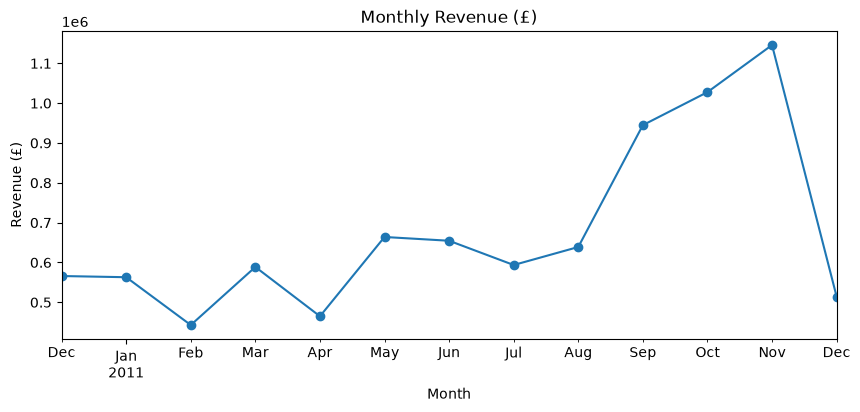

In [17]:
plot_monthly_revenue(df)  # function call karke chart 1 banao

### 💡 Two quick business facts (numbers instead of more charts)
The **Pareto rule** (80/20) – do a few customers give most of the money? And which countries matter?

In [18]:
cust_rev = df.groupby("Customer ID")["Revenue"].sum().sort_values(ascending=False)  # har customer ka total kharch, sabse zyada upar
top20 = cust_rev.head(int(len(cust_rev) * 0.2)).sum() / cust_rev.sum()  # top 20% customers se aane wale revenue ka hissa
print(f"Top 20% customers give {top20:.1%} of the revenue")  # Pareto ka result print karo

Top 20% customers give 74.7% of the revenue


In [19]:
country_rev = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)  # har country ka revenue, sabse zyada upar
(country_rev.head(5) / country_rev.sum()).round(3)  # top 5 countries ka revenue hissa

Country
United Kingdom    0.826
Netherlands       0.032
EIRE              0.030
Germany           0.024
France            0.022
Name: Revenue, dtype: float64

## 6. Feature Engineering – Har Customer Ki Ek Row Banao
Raw data mein har product line ki ek row hai. Machine learning ke liye humein **har customer ki ek row** chahiye.

⚠️ **Data leakage se bachna (interviews ke liye bahut important):**
Hum ek **cutoff date** chunte hain = **data khatam hone se 90 din pehle**.
- Features (inputs) sirf **cutoff se PEHLE ki purchases** se bante hain (past).
- Targets (jo hum predict karte hain) sirf **cutoff ke BAAD ki purchases** se bante hain (future).

Isliye model seekhte time kabhi future nahi dekhta – bilkul real life ki tarah.

In [20]:
cutoff = df["InvoiceDate"].max() - pd.Timedelta(days=90)  # hamara "aaj": data khatam hone se 90 din pehle
past = df[df["InvoiceDate"] < cutoff]  # cutoff se pehle ki purchases (features ke liye)
future = df[df["InvoiceDate"] >= cutoff]  # cutoff ke baad ki purchases (target ke liye)
print(cutoff)  # cutoff date dikhao

2011-09-10 12:50:00


### RFM features
- **Recency** – last purchase ko kitne din ho gaye (kam = active customer)
- **Frequency** – orders ki kul sankhya
- **Monetary** – kul kharch kiya hua paisa

Hum kuch aur easy features bhi add karte hain: total items, unique products, customer age, average order value, cutoff se pehle ke aakhri 90 din ka spend, aur ek UK flag.

In [21]:
def make_features(past, cutoff):  # function jo past data se har customer ki ek row banata hai
    g = past.groupby("Customer ID")  # past purchases ko customer ke hisaab se group kiya
    feat = g["Revenue"].sum().to_frame("Monetary")  # Monetary: har customer ne kul kitna paisa kharch kiya
    feat["Frequency"] = g["Invoice"].nunique()  # Frequency: orders ki ginti
    feat["Recency"] = (cutoff - g["InvoiceDate"].max()).dt.days  # Recency: aakhri purchase ko kitne din hue
    feat["TotalItems"] = g["Quantity"].sum()  # kul kitne items kharide
    feat["UniqueProducts"] = g["StockCode"].nunique()  # kitne alag-alag products kharide
    feat["CustomerAgeDays"] = (cutoff - g["InvoiceDate"].min()).dt.days  # pehli purchase ko kitne din hue
    feat["AvgOrderValue"] = feat["Monetary"] / feat["Frequency"]  # ek order ka average paisa
    return feat  # feature table wapas bhej diya

In [22]:
feat = make_features(past, cutoff)  # customer table banao
recent = past[past["InvoiceDate"] >= cutoff - pd.Timedelta(days=90)]  # cutoff se pehle ke aakhri 90 din ki purchases
feat["Spend_Last90"] = recent.groupby("Customer ID")["Revenue"].sum()  # un 90 dinon ka kharch (customer id se match hua)
feat["Spend_Last90"] = feat["Spend_Last90"].fillna(0)  # jisne recent purchase nahi ki use 0 mila
feat["IsUK"] = (past.groupby("Customer ID")["Country"].first() == "United Kingdom").astype(int)  # 1 agar customer UK ka hai

### Targets (what we want to predict) – from the FUTURE data
- `FutureSpend` – money spent in the next 90 days
- `WillBuy` – 1 if the customer bought again, else 0

In [23]:
feat["FutureSpend"] = future.groupby("Customer ID")["Revenue"].sum()  # har customer ka future kharch (customer id se match hua)
feat["FutureSpend"] = feat["FutureSpend"].fillna(0)  # jo customer dobara nahi kharide unhe 0 mila
feat["WillBuy"] = (feat["FutureSpend"] > 0).astype(int)  # 1 = dobara kharida, 0 = nahi kharida
feat.shape  # customers x columns

(3370, 11)

In [24]:
feat.head()  # customer table ki jhalak

,Monetary,Frequency,Recency,TotalItems,UniqueProducts,CustomerAgeDays,AvgOrderValue,Spend_Last90,IsUK,FutureSpend,WillBuy
Customer ID,,,,,,,,,,,
12346,77183.60,1,235,74215,1,235,77183.600,0.00,1,0.00,0
12347,2790.86,5,39,1590,82,276,558.172,584.91,0,1519.14,1
12348,1167.24,3,158,2116,21,267,389.080,0.00,0,270.00,1
12350,294.40,1,219,196,16,219,294.400,0.00,0,0.00,0
12352,1481.81,5,171,252,25,206,296.362,0.00,0,744.23,1


In [25]:
feat["WillBuy"].value_counts(normalize=True)  # kitne customers ne dobara kharida (1) aur kitno ne nahi (0), hissa

WillBuy
1    0.569733
0    0.430267
Name: proportion, dtype: float64

## 7. Part A – Classification: Will the Customer Buy Again in 90 Days?
**Target:** `WillBuy` (1 = yes, 0 = no).

**Steps:**
1. Take the log of very skewed columns (a few huge customers should not confuse the model).
2. Split 80% train / 20% test (same class ratio in both).
3. Scale the columns – the scaler learns **only from train data** (no leakage).

In [26]:
FEATURES = ["Recency", "Frequency", "Monetary", "TotalItems", "UniqueProducts", "CustomerAgeDays", "AvgOrderValue", "Spend_Last90", "IsUK"]  # saare models ke input columns
SKEWED = ["Frequency", "Monetary", "TotalItems", "UniqueProducts", "AvgOrderValue", "Spend_Last90"]  # paise aur ginti wale columns jo bahut skewed hain

In [27]:
X = feat[FEATURES].copy()  # input table
X[SKEWED] = np.log1p(X[SKEWED])  # log(1+x) bahut bade values ka asar kam karta hai
y_class = feat["WillBuy"]  # classification ka target

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.2, random_state=42, stratify=y_class)  # 80/20 split, class ka ratio same rakhte hue
print(X_train.shape, X_test.shape)  # dono hisson ka size

(2696, 9) (674, 9)


In [29]:
scaler = StandardScaler()  # scaler banaya
X_train_s = scaler.fit_transform(X_train)  # scaling train data se seekhi aur lagayi
X_test_s = scaler.transform(X_test)  # wahi scaling test data par lagayi

### Create and train the models 
Every model is **trained on the train data**. After that we measure each model on **both train data and test data**.

In [30]:
model_lr = LogisticRegression(max_iter=1000)  # logistic regression
model_knn = KNeighborsClassifier(n_neighbors=15)  # KNN jo 15 sabse paas ke customers dekhta hai
model_nb = GaussianNB()  # Gaussian Naive Bayes
model_dt = DecisionTreeClassifier(max_depth=5, random_state=42)  # decision tree, depth limit ki taaki overfitting na ho
model_rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)  # 200 trees ka random forest

In [31]:
model_lr.fit(X_train_s, y_train)  # logistic regression ko train data par train kiya
model_knn.fit(X_train_s, y_train)  # KNN ko train data par train kiya
model_nb.fit(X_train_s, y_train)  # Gaussian Naive Bayes ko train data par train kiya
model_dt.fit(X_train_s, y_train)  # decision tree ko train data par train kiya
model_rf.fit(X_train_s, y_train)  # random forest ko train data par train kiya

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

### Helper function to score any model on any data
One function, used for every model and for both train and test data → short code, easy to explain.
- **Accuracy** – how many predictions are right overall
- **Precision** – of the customers we said "will buy", how many really bought
- **Recall** – of the customers who really bought, how many we caught
- **F1** – balance of precision and recall

In [32]:
def get_clf_scores(model, X, y, name):  # function jo kisi bhi data par model ke scores deta hai
    pred = model.predict(X)             # model se predictions li
    return {                            # saare scores ek dictionary mein
        "Model": name,                  # model ka naam
        "Accuracy": accuracy_score(y, pred),  # kul kitni predictions sahi hain
        "Precision": precision_score(y, pred, zero_division=0),  # "will buy" predictions kitni sahi hain
        "Recall": recall_score(y, pred, zero_division=0),  # kitne asli buyers pakde
        "F1": f1_score(y, pred, zero_division=0),  # precision aur recall ka balance
    }  # dictionary khatam

### Scores on TRAIN data and on TEST data
Same function, only the data changes. Compare both tables to check **overfitting**.

In [33]:
results_train = pd.DataFrame([  # train data ke scores, har model ki ek row
    get_clf_scores(model_lr, X_train_s, y_train, "Logistic Regression"),  # logistic regression ke train scores
    get_clf_scores(model_knn, X_train_s, y_train, "KNN"),  # KNN ke train scores
    get_clf_scores(model_nb, X_train_s, y_train, "Gaussian NB"),  # Gaussian Naive Bayes ke train scores
    get_clf_scores(model_dt, X_train_s, y_train, "Decision Tree"),  # decision tree ke train scores
    get_clf_scores(model_rf, X_train_s, y_train, "Random Forest"),  # random forest ke train scores
])  # train table khatam

In [34]:
results_test = pd.DataFrame([  # test data ke scores, har model ki ek row
    get_clf_scores(model_lr, X_test_s, y_test, "Logistic Regression"),  # logistic regression ke test scores
    get_clf_scores(model_knn, X_test_s, y_test, "KNN"),  # KNN ke test scores
    get_clf_scores(model_nb, X_test_s, y_test, "Gaussian NB"),  # Gaussian Naive Bayes ke test scores
    get_clf_scores(model_dt, X_test_s, y_test, "Decision Tree"),  # decision tree ke test scores
    get_clf_scores(model_rf, X_test_s, y_test, "Random Forest"),  # random forest ke test scores
])  # test table khatam

In [35]:
results_train.round(3)  # TRAIN data ke scores dikhao

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.685,0.726,0.717,0.721
1,KNN,0.706,0.735,0.757,0.746
2,Gaussian NB,0.668,0.754,0.618,0.679
3,Decision Tree,0.707,0.759,0.711,0.734
4,Random Forest,0.819,0.855,0.821,0.838


In [36]:
results_test.round(3).sort_values("F1", ascending=False)  # TEST data ke scores, sabse achha model upar

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.694,0.742,0.711,0.726
4,Random Forest,0.687,0.729,0.716,0.723
3,Decision Tree,0.674,0.724,0.690,0.707
1,KNN,0.651,0.680,0.734,0.706
2,Gaussian NB,0.681,0.777,0.617,0.688


### 🔍 Overfitting check: Train minus Test
If a number is **much bigger** on train than on test (big positive gap), the model has memorised the train data = **overfitting**.

In [37]:
gap_clf = results_train.set_index("Model") - results_test.set_index("Model")  # train score minus test score
gap_clf.round(3)  # gap dikhao (bada positive gap = overfitting)

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,-0.010,-0.016,0.006,-0.005
KNN,0.055,0.055,0.023,0.040
Gaussian NB,-0.013,-0.023,0.001,-0.009
Decision Tree,0.033,0.035,0.021,0.028
Random Forest,0.132,0.126,0.105,0.115


### Baseline to beat (simple pandas)
If we just guess the **most common class** for every customer, how accurate are we? A real model must beat this number, otherwise it is useless.

In [38]:
baseline_acc = y_test.value_counts(normalize=True).max()  # sabse common class ka hissa = hamesha wahi guess karne par accuracy
print("Baseline accuracy:", round(baseline_acc, 3))  # baseline accuracy print karo

Baseline accuracy: 0.57


### Pick the best model
We choose by **F1 on the test data** (balance of precision and recall).

In [39]:
models_clf = {"Logistic Regression": model_lr, "KNN": model_knn, "Gaussian NB": model_nb, "Decision Tree": model_dt, "Random Forest": model_rf}  # naam -> trained model
best_name = results_test.sort_values("F1", ascending=False).iloc[0]["Model"]  # F1 ke hisaab se sabse achhe model ka naam
best_model = models_clf[best_name]  # sabse achha trained model
pred_best = best_model.predict(X_test_s)  # test data par uski predictions
print(best_name)  # winner dikhao

Logistic Regression


### 📊 Chart 2 – Confusion Matrix of the Best Model
- **Top-left (TN)** – said "will not buy", really did not buy ✅
- **Bottom-right (TP)** – said "will buy", really bought ✅
- **Top-right (FP)** – said "will buy", but did not buy ❌ (wasted offer)
- **Bottom-left (FN)** – said "will not buy", but bought ❌ (missed customer)

In [40]:
def plot_confusion(y_true, y_pred, title):  # function jo confusion matrix banata hai
    cm = confusion_matrix(y_true, y_pred)  # sahi aur galat predictions ginti
    plt.figure(figsize=(4.5, 3.5))  # chart ka size
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Will not buy", "Will buy"], yticklabels=["Will not buy", "Will buy"])  # numbers ke saath rangin grid
    plt.xlabel("Predicted")  # x axis ka label
    plt.ylabel("Actual")  # y axis ka label
    plt.title(title)  # chart ka title
    plt.show()  # chart dikhao

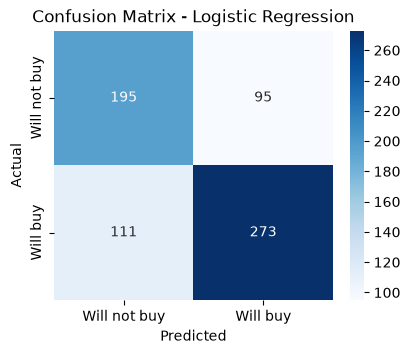

Monetary           0.178
Frequency          0.174
UniqueProducts     0.128
TotalItems         0.128
Recency            0.117
AvgOrderValue      0.103
CustomerAgeDays    0.086
Spend_Last90       0.079
IsUK               0.007
dtype: float64

In [41]:
plot_confusion(y_test, pred_best, f"Confusion Matrix - {best_name}")  # function call karke chart 2 banao
imp = pd.Series(model_rf.feature_importances_, index=FEATURES)  # har input column ki importance
imp.sort_values(ascending=False).round(3)  # sabse important columns pehle dikhao

(regression: data, split, models)

In [42]:
reg_data = feat[feat["WillBuy"] == 1]  # sirf wo customers jinhone agle 90 din mein kharida
X_reg = X.loc[reg_data.index]  # unke input features
y_reg = np.log1p(reg_data["FutureSpend"])  # future kharch ka log (kharch bahut skewed hai)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)  # 80/20 split
scaler_r = StandardScaler()  # naya scaler
Xr_train_s = scaler_r.fit_transform(Xr_train)  # scaling train data se seekhi aur lagayi
Xr_test_s = scaler_r.transform(Xr_test)  # wahi scaling test data par lagayi
reg_lr = LinearRegression().fit(Xr_train_s, yr_train)  # linear regression banaya aur train kiya
reg_knn = KNeighborsRegressor(n_neighbors=15).fit(Xr_train_s, yr_train)  # KNN banaya aur train kiya
reg_dt = DecisionTreeRegressor(max_depth=5, random_state=42).fit(Xr_train_s, yr_train)  # decision tree banaya aur train kiya
reg_rf = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42).fit(Xr_train_s, yr_train)  # random forest banaya aur train kiya

(regression: errors)

In [43]:
def reg_errors(model, X, y_log):  # function jo kisi bhi data par model ke errors £ mein deta hai
    pred = np.expm1(model.predict(X))  # predictions ko wapas £ mein badla
    actual = np.expm1(y_log)  # asli values ko wapas £ mein badla
    mse = mean_squared_error(actual, pred)  # mean squared error
    return pd.Series({"MAE": mean_absolute_error(actual, pred), "MSE": mse, "RMSE": np.sqrt(mse), "MAPE %": mean_absolute_percentage_error(actual, pred) * 100, "R2": r2_score(actual, pred)})  # saare errors ek Series mein
models_reg = pd.Series({"Linear Regression": reg_lr, "KNN": reg_knn, "Decision Tree": reg_dt, "Random Forest": reg_rf})  # naam -> trained model
reg_train = models_reg.apply(reg_errors, args=(Xr_train_s, yr_train))  # har model ke TRAIN errors (loop nahi)
reg_test = models_reg.apply(reg_errors, args=(Xr_test_s, yr_test))  # har model ke TEST errors
print(reg_train.round(2))  # TRAIN errors dikhao
print(reg_test.round(2).sort_values("MAE"))  # TEST errors dikhao, sabse kam MAE upar

                      MAE          MSE     RMSE  MAPE %    R2
Linear Regression  756.95  13203057.68  3633.60  103.96  0.47
KNN                789.97  17160701.43  4142.55   87.64  0.31
Decision Tree      623.10   7209847.44  2685.12   74.35  0.71
Random Forest      537.72   5678303.93  2382.92   54.29  0.77
                       MAE           MSE      RMSE  MAPE %    R2
Decision Tree      1019.79  7.615385e+07   8726.62   91.48  0.34
Random Forest      1126.66  8.861415e+07   9413.51   86.71  0.23
Linear Regression  1180.72  9.998289e+07   9999.14   81.78  0.14
KNN                1259.73  1.072814e+08  10357.67   85.68  0.07


(elbow chart, chart 3)

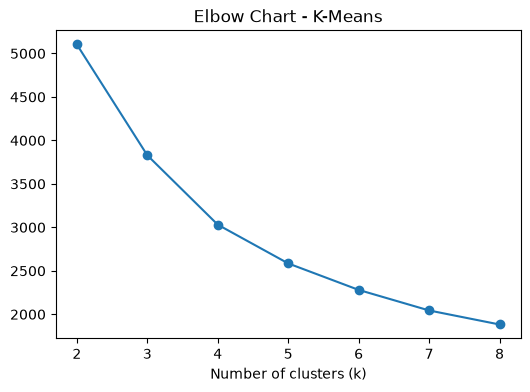

In [44]:
rfm = np.log1p(feat[["Recency", "Frequency", "Monetary"]])  # RFM columns ka log, skew kam karne ke liye
X_rfm = StandardScaler().fit_transform(rfm)  # scale kiya taaki har column ka weight barabar ho
def get_inertia(k):  # function jo ek k ke liye K-Means ka inertia deta hai
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_rfm)  # k clusters wala K-Means banaya aur fit kiya
    return km.inertia_  # clusters kitne tight hain (kam = zyada tight)
ks = pd.Series(range(2, 9))  # k ki values: 2 se 8
inertias = ks.apply(get_inertia)  # har k ke liye function chalaya (loop nahi)
inertias.index = ks  # chart ke x axis par k dikhane ke liye
inertias.plot(marker="o", figsize=(6, 4), title="Elbow Chart - K-Means")  # chart 3: elbow chart
plt.xlabel("Number of clusters (k)")  # x axis ka label
plt.show()  # chart dikhao

(K-Means, hierarchical, segments)

In [46]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)  # 4 segments wala final K-Means
feat["Cluster"] = kmeans.fit_predict(X_rfm)  # har customer ko segment number diya
print("Silhouette:", round(silhouette_score(X_rfm, feat["Cluster"], sample_size=3000, random_state=42), 3))  # segments kitne alag hain (zyada = behtar)
sample = pd.DataFrame(X_rfm).sample(frac=0.5, random_state=42)  # customers ka random 50% (hierarchical dheema hota hai)
hier_labels = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(sample)  # hierarchical clustering ke labels
km_labels = kmeans.predict(sample.values)  # wahi customers ke K-Means labels
print("Hierarchical silhouette:", round(silhouette_score(sample, hier_labels), 3))  # hierarchical ki quality
print("Agreement with K-Means:", round(adjusted_rand_score(hier_labels, km_labels), 3))  # dono methods kitna sahmat hain
segments = feat.groupby("Cluster")[["Recency", "Frequency", "Monetary", "WillBuy", "FutureSpend"]].mean().round(2)  # har segment ka average
segments["Customers"] = feat["Cluster"].value_counts()  # har segment mein customers ki ginti
segments.sort_values("Monetary", ascending=False)  # sabse zyada kharch karne wala segment upar

Silhouette: 0.375
Hierarchical silhouette: 0.384
Agreement with K-Means: 0.409


,Recency,Frequency,Monetary,WillBuy,FutureSpend,Customers
Cluster,,,,,,
2,15.90,12.19,6815.37,0.93,3334.74,469
0,78.99,3.41,1497.40,0.67,583.77,1009
3,13.89,2.17,598.21,0.59,505.12,446
1,155.74,1.21,287.92,0.37,308.31,1446


(final numbers)

In [47]:
actual = np.expm1(yr_test)  # test customers ka asli future kharch £ mein
baseline_mae = (actual - actual.mean()).abs().mean()  # hamesha average kharch guess karein to average error
clf = results_test.set_index("Model").loc[best_name]  # best classifier ke test scores
best_reg = reg_test["MAE"].idxmin()  # sabse kam MAE wala regressor
print("Best classifier:", best_name, "| F1:", round(clf["F1"], 3), "| Recall:", round(clf["Recall"], 3), "| Accuracy:", round(clf["Accuracy"], 3), "| Baseline acc:", round(baseline_acc, 3))  # classifier ka result
print("Best regressor:", best_reg, "| MAE: £", round(reg_test.loc[best_reg, "MAE"]), "| Baseline MAE: £", round(baseline_mae))  # regressor ka result
print(f"Top 20% customers give {top20:.1%} of revenue")  # Pareto ka fact

Best classifier: Logistic Regression | F1: 0.726 | Recall: 0.711 | Accuracy: 0.694 | Baseline acc: 0.57
Best regressor: Decision Tree | MAE: £ 1020 | Baseline MAE: £ 2081
Top 20% customers give 74.7% of revenue


In [56]:
acutal = np.expm1(yr_test)
baseline_mae = (actual -actual.mean()).abs().mean()
clf = results_test.set_index('Model').loc[best_name]
best_reg = reg_test['MAE'].idxmin()
print('Best classifier:', best_name, '| F1:',round(clf['F1'],3),'|Recall:',round(clf['Recall'],3),'| Accuracy:', round(clf['Accuracy'],3), '| Baseline acc:', round(baseline_acc,3))
print('Best regressor:',best_reg, 'MAE:',round(reg_test.loc[best_reg, 'MAE']),'| Baseline MAE:', round(baseline_mae))
print(f"Top 20% customers give {top20:.1%} of revenue")

Best classifier: Logistic Regression | F1: 0.726 |Recall: 0.711 | Accuracy: 0.694 | Baseline acc: 0.57
Best regressor: Decision Tree MAE: 1020 | Baseline MAE: 2081
Top 20% customers give 74.7% of revenue
